# MNIST CNN 32×32 — re-training for STM32N6570-DK (October 2026)

Same model and training procedure as `mnist_cnn_augmented.ipynb` (June 2026). Changes, all for reproducibility:
1. fixed random seed;
2. calibration data for quantisation taken from the **training** split (not from the test set);
3. float accuracy measured on the full test set **and** on the first 500 test images used by the on-board benchmark (`TEST_MODE 2`), with per-image predictions saved;
4. every artefact is saved and downloaded (Keras model, ONNX, calibration file, predictions, metrics).

**Run all cells in order** (Runtime → Run all). A GPU runtime is optional.

In [ ]:
import json, numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

def preprocess(images):
    images = images[..., np.newaxis].astype('float32') / 255.0  # [N,28,28,1], range [0,1]
    images = tf.image.resize(images, [32, 32]).numpy()           # [N,32,32,1]
    images = np.repeat(images, 3, axis=-1)                       # [N,32,32,3]
    return images

x_train = preprocess(x_train)
x_test  = preprocess(x_test)
print('Train:', x_train.shape, '| Test:', x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 32, 32, 3) | Test: (10000, 32, 32, 3)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=10,
    fill_mode='constant',
    cval=0.0
)

# Fit on a subset (computes internal statistics if needed)
datagen.fit(x_train[:1000])

In [ ]:
inputs  = tf.keras.Input(shape=(32, 32, 3), name='input')
x = tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu')(inputs)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(64, activation='relu')(x)
outputs = tf.keras.layers.Dense(10, activation='softmax', name='output')(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,394 (110.91 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Split off 10% of training data for validation (same as original)
val_split = int(len(x_train) * 0.1)
x_val, y_val = x_train[:val_split], y_train[:val_split]
x_tr,  y_tr  = x_train[val_split:], y_train[val_split:]

BATCH_SIZE     = 128
EPOCHS         = 20
steps_per_epoch = len(x_tr) // BATCH_SIZE

history = model.fit(
    datagen.flow(x_tr, y_tr, batch_size=BATCH_SIZE),
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(x_val, y_val),
    verbose=1
)

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f'\nTest accuracy on clean MNIST: {acc:.4f}')

Epoch 1/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 108s 253ms/step - accuracy: 0.5269 - loss: 1.3626 - val_accuracy: 0.8587 - val_loss: 0.4918
Epoch 2/20
  1/421 ━━━━━━━━━━━━━━━━━━━━ 1:01 147ms/step - accuracy: 0.8203 - loss: 0.6374

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8203 - loss: 0.6374 - val_accuracy: 0.8730 - val_loss: 0.4669
Epoch 3/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 139s 252ms/step - accuracy: 0.8442 - loss: 0.5260 - val_accuracy: 0.9267 - val_loss: 0.2708
Epoch 4/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8672 - loss: 0.3976 - val_accuracy: 0.9272 - val_loss: 0.2698
Epoch 5/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 137s 246ms/step - accuracy: 0.8857 - loss: 0.3850 - val_accuracy: 0.9082 - val_loss: 0.3065
Epoch 6/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7969 - loss: 0.5008 - val_accuracy: 0.9177 - val_loss: 0.2690
Epoch 7/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 104s 247ms/step - accuracy: 0.9066 - loss: 0.3117 - val_accuracy: 0.9460 - val_loss: 0.1963
Epoch 8/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9453 - loss: 0.1904 - val_accuracy: 0.9477 - val_loss: 0.1946
Epoch 9/20
421/421 ━━━━━━━━━━━━━━━━━━━━ 144s 260ms/step - accuracy: 0.9221 - loss: 0.2616 - val_accurac

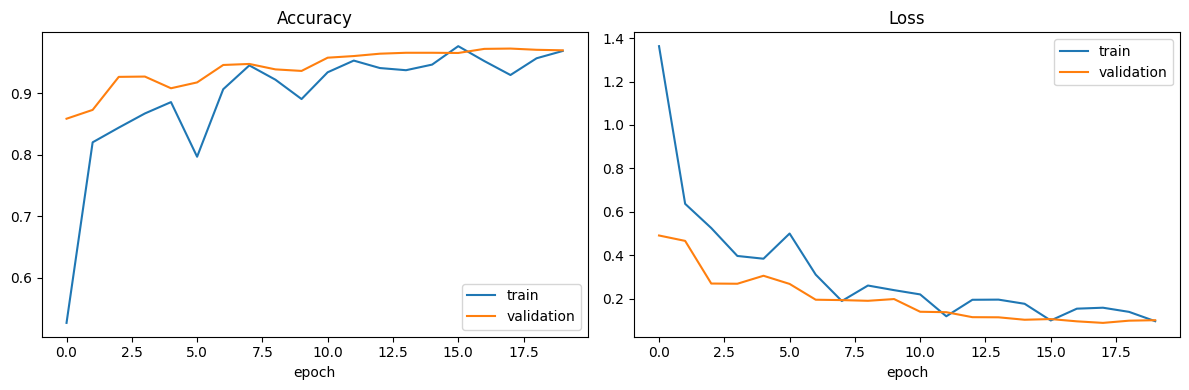

In [ ]:
# Training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['accuracy'], label='train'); ax1.plot(history.history['val_accuracy'], label='validation')
ax1.set_title('Accuracy'); ax1.set_xlabel('epoch'); ax1.legend()
ax2.plot(history.history['loss'], label='train'); ax2.plot(history.history['val_loss'], label='validation')
ax2.set_title('Loss'); ax2.set_xlabel('epoch'); ax2.legend()
plt.tight_layout(); plt.savefig('training_curves.png', dpi=120); plt.show()

## Float reference accuracy (same images as the on-board benchmark)

In [ ]:
prob_test = model.predict(x_test, verbose=0)
pred_test = prob_test.argmax(1)
acc_full  = float((pred_test == y_test).mean())
acc_500   = float((pred_test[:500] == y_test[:500]).mean())
print(f'Float accuracy, full test set (10 000): {acc_full*100:.2f}%')
print(f'Float accuracy, first 500 test images : {acc_500*100:.2f}%  (same images as TEST_MODE 2 on the board)')

# Confusion matrix on the first 500 (rows = true, cols = predicted)
cm = np.zeros((10, 10), int)
for t, p in zip(y_test[:500], pred_test[:500]): cm[t, p] += 1
print(cm)

np.save('float_pred_first500.npy', pred_test[:500])
metrics = {'seed': SEED, 'tf_version': tf.__version__, 'epochs': EPOCHS,
           'float_acc_test_10000': acc_full, 'float_acc_test_first500': acc_500,
           'final_val_acc': float(history.history['val_accuracy'][-1]),
           'confusion_first500': cm.tolist()}
json.dump(metrics, open('float_metrics.json', 'w'), indent=2)

Float accuracy, full test set (10 000): 96.81%
Float accuracy, first 500 test images : 96.60%  (same images as TEST_MODE 2 on the board)
[[41  0  0  0  0  0  0  0  0  1]
 [ 0 67  0  0  0  0  0  0  0  0]
 [ 0  0 55  0  0  0  0  0  0  0]
 [ 0  0  1 43  0  1  0  0  0  0]
 [ 0  0  1  0 51  0  1  0  2  0]
 [ 0  1  1  0  0 48  0  0  0  0]
 [ 0  0  0  0  0  0 43  0  0  0]
 [ 0  0  0  1  0  0  0 48  0  0]
 [ 0  0  1  1  0  1  0  0 36  1]
 [ 0  0  0  2  0  1  0  0  0 51]]


## Export: Keras, ONNX and calibration data

In [ ]:
!pip install tf2onnx -q
import tf2onnx

model.save('mnist_cnn_32x32.keras')

input_sig = [tf.TensorSpec((None, 32, 32, 3), tf.float32, name='input')]
model_proto, _ = tf2onnx.convert.from_keras(model, input_signature=input_sig, opset=13)
with open('mnist_cnn_32x32.onnx', 'wb') as f:
    f.write(model_proto.SerializeToString())

# Calibration data for quantisation: 300 random images from the TRAINING split
# (not the test set, so that the test images stay completely unseen)
rng = np.random.default_rng(SEED)
calib_idx = rng.choice(len(x_tr), 300, replace=False)
np.savez('mnist_calib.npz', input_1=x_tr[calib_idx].astype('float32'))
print('Saved: mnist_cnn_32x32.keras, mnist_cnn_32x32.onnx, mnist_calib.npz')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 95.6 MB/s eta 0:00:00
Saved: mnist_cnn_32x32.keras, mnist_cnn_32x32.onnx, mnist_calib.npz


In [ ]:
from google.colab import files
for f in ['mnist_cnn_32x32.onnx', 'mnist_cnn_32x32.keras', 'mnist_calib.npz',
          'float_metrics.json', 'float_pred_first500.npy', 'training_curves.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## After quantisation on ST Edge AI Developer Cloud

Upload here the **quantised** model downloaded from the Developer Cloud (`*_quant_*.onnx`), then run the cell below:
it measures the int8 accuracy on the PC on the same 500 images, to compare with the board.

In [ ]:
!pip install onnxruntime -q
import onnxruntime as ort
from google.colab import files
up = files.upload()                       # choose the quantised .onnx
qpath = list(up.keys())[0]
sess = ort.InferenceSession(qpath)
inp = sess.get_inputs()[0]; print('input:', inp.name, inp.type, inp.shape)
x = x_test[:500].astype('float32')
if 'int8' in inp.type:                    # model with int8 input: quantise as on the board
    x = np.round(x * 255.0 - 128.0).clip(-128, 127).astype(np.int8)
out = sess.run(None, {inp.name: x})[0]
pred_q = out.reshape(500, -1).argmax(1)
acc_q = float((pred_q == y_test[:500]).mean())
agree = float((pred_q == pred_test[:500]).mean())
print(f'int8 accuracy on PC, first 500: {acc_q*100:.2f}%   agreement with float: {agree*100:.1f}%')
np.save('int8_pc_pred_first500.npy', pred_q)
metrics['int8_pc_acc_first500'] = acc_q; metrics['int8_float_agreement_first500'] = agree
json.dump(metrics, open('float_metrics.json', 'w'), indent=2)
files.download('int8_pc_pred_first500.npy'); files.download('float_metrics.json')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 32.8 MB/s eta 0:00:00


KeyboardInterrupt: 